# Adaptation of Heo et al. (2021) Classifiers to Anxolotl Dataset

**Original paper:** Heo S., Kwon S., Lee J. — *Stress Detection With Single PPG Sensor by Orchestrating Multiple Denoising and Peak-Detecting Methods* — IEEE Access, 2021  
**Original code:** https://github.com/seongsilheo/stress_classification_with_PPG  
**Original dataset:** WESAD (Wearable Stress and Affect Detection)

---

**What this notebook does:**  
Adapts the same 7 classifiers used in Heo et al. to the Anxolotl dataset. The original pipeline processes raw PPG signals (BVP at 64 Hz from Empatica E4) through bandpass filtering, noise elimination, and ensemble peak detection. Since Anxolotl only provides pre-computed HR and IBI (from Garmin/Apple Watch), we skip the signal processing step and apply the classifiers directly to the extracted HRV features.

Two normalization strategies are compared on the **same dataset and same classifiers** to isolate the effect of normalization:
- **StandardScaler** — used by Heo et al.: fit on training set, transform test set
- **Baseline-Relative (BL-norm)** — our approach: normalize per subject relative to their own resting baseline

**Feature overlap with their 27 PPG features:**

| Heo et al. feature | Anxolotl equivalent | Available |
|---|---|---|
| HR_mean, HR_std | hr_mean, hr_std | ✓ |
| meanNN (mean IBI) | ibi_mean | ✓ |
| SDNN | sdnn_mean | ✓ |
| RMSSD | rmssd_mean | ✓ |
| LFHF | ibi_lf_hf | ✓ (ratio only) |
| SD1 | rmssd_mean / √2 | ✓ (derived) |
| SD2 | √(2·sdnn² − 0.5·rmssd²) | ✓ (derived) |
| pNN20, pNN50, TINN | — | ✗ |
| LF, HF, ULF, VLF | — | ✗ |
| ApEn, shanEn, D2 | — | ✗ |

In [1]:
import pickle
import numpy as np
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier, AdaBoostClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn import tree, svm
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score

import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = '../processed_data/anxolotl/processed_data_anxolotl.pkl'

with open(DATA_PATH, 'rb') as f:
    data = pickle.load(f)

X_all = np.array(data['X'], dtype=float)
y_all = np.array(data['y'])
groups_all = np.array(data['groups'])
feature_cols = data['feature_cols']

print(f'Windows: {X_all.shape[0]}, Features: {X_all.shape[1]}')
print(f'Subjects: {len(np.unique(groups_all))}')
print(f'Stress: {y_all.sum()}, Baseline: {(y_all==0).sum()}')

Windows: 712, Features: 60
Subjects: 37
Stress: 413, Baseline: 299


## Normalization strategies

In [ ]:
def baseline_relative_scale(X, y, groups):
    """Normalize per subject relative to their own resting baseline (label=0 windows).
    Fixed 2026-07-19: reference is now the subject's leading run of baseline-labelled
    windows (initial ~5min rest, always first by protocol design), not every y==0 row
    anywhere in the timeline. The previous version let a fold (including the test fold)
    build its own normalisation reference from its own true labels -- a structural leak
    confirmed via label permutation and a pure-noise control (see 3_anxolotl/demographics_analysis.py).
    """
    X = np.array(X, dtype=float).copy()
    y = np.array(y)
    groups = np.array(groups)
    for subj in np.unique(groups):
        subj_idx = np.where(groups == subj)[0]
        n_baseline = 0
        for v in y[subj_idx]:
            if v == 0:
                n_baseline += 1
            else:
                break
        baseline_idx = subj_idx[:n_baseline]
        if len(baseline_idx) > 1:
            for j in range(X.shape[1]):
                col_bl = X[baseline_idx, j]
                valid = col_bl[~np.isnan(col_bl)]
                if len(valid) > 1:
                    mu, sd = valid.mean(), valid.std()
                    X[subj_idx, j] = (X[subj_idx, j] - mu) / (sd + 1e-8)
    return X

## Classifiers from Heo et al. (2021)
Exact same 7 classifiers and hyperparameters as in `ML_binary.py`.

In [3]:
def make_classifiers():
    return {
        'DT':  tree.DecisionTreeClassifier(random_state=0),
        'RF':  RandomForestClassifier(max_depth=4, random_state=0),
        'AB':  AdaBoostClassifier(random_state=0),
        'KN':  KNeighborsClassifier(n_neighbors=9),
        'LDA': LinearDiscriminantAnalysis(),
        'SVM': svm.SVC(probability=True),
        'GB':  GradientBoostingClassifier(random_state=0),
    }

## LOSO-CV — both normalizations

`norm='standard'` replicates Heo et al.: StandardScaler fit on train, applied to test.  
`norm='blnorm'` uses baseline-relative normalization per subject.

In [4]:
def run_loso(X, y, groups, norm='blnorm'):
    classifiers = make_classifiers()
    subjects = np.unique(groups)
    results = {name: {'auc': [], 'f1': [], 'acc': []} for name in classifiers}
    subject_list = []

    for subj in subjects:
        test_mask  = groups == subj
        train_mask = ~test_mask

        X_train, y_train = X[train_mask], y[train_mask]
        X_test,  y_test  = X[test_mask],  y[test_mask]

        if norm == 'standard':
            sc = StandardScaler()
            X_train_n = sc.fit_transform(np.nan_to_num(X_train))
            X_test_n  = sc.transform(np.nan_to_num(X_test))
        else:  # blnorm
            X_train_n = np.nan_to_num(baseline_relative_scale(X_train, y_train, groups[train_mask]))
            X_test_n  = np.nan_to_num(baseline_relative_scale(X_test,  y_test,  groups[test_mask]))

        subject_list.append(subj)
        for name, clf in classifiers.items():
            clf.fit(X_train_n, y_train)
            y_pred = clf.predict(X_test_n)
            try:
                y_prob = clf.predict_proba(X_test_n)[:, 1]
                auc = roc_auc_score(y_test, y_prob)
            except:
                auc = roc_auc_score(y_test, y_pred)
            results[name]['auc'].append(auc)
            results[name]['f1'].append(f1_score(y_test, y_pred, average='binary', zero_division=0))
            results[name]['acc'].append(accuracy_score(y_test, y_pred))

    return results, subject_list

print('Running LOSO — StandardScaler...')
res_std, subjects = run_loso(X_all, y_all, groups_all, norm='standard')
print('Running LOSO — BL-norm...')
res_bl,  _        = run_loso(X_all, y_all, groups_all, norm='blnorm')
print('Done.')

Running LOSO — StandardScaler...


Running LOSO — BL-norm...


Done.


## StandardScaler vs BL-norm — effect of normalization on the same dataset

Both columns use the same classifiers, same Anxolotl data, same LOSO split.  
Only the normalization differs — this isolates the contribution of BL-norm.

In [5]:
clf_names = list(make_classifiers().keys())

rows = []
for name in clf_names:
    f1_std = np.mean(res_std[name]['f1'])
    f1_bl  = np.mean(res_bl[name]['f1'])
    auc_std = np.mean(res_std[name]['auc'])
    auc_bl  = np.mean(res_bl[name]['auc'])
    rows.append({
        'Classifier':       name,
        'F1 StandardScaler': f'{f1_std:.3f}',
        'F1 BL-norm':        f'{f1_bl:.3f}',
        'ΔF1':               f'{f1_bl - f1_std:+.3f}',
        'AUC StandardScaler': f'{auc_std:.3f}',
        'AUC BL-norm':        f'{auc_bl:.3f}',
        'ΔAUC':               f'{auc_bl - auc_std:+.3f}',
    })

cmp_df = pd.DataFrame(rows).set_index('Classifier')
print('Anxolotl LOSO-CV — StandardScaler (Heo et al.) vs BL-norm (this work)')
print('Binary F1 (stress class), same classifiers, same data')
print()
print(cmp_df.to_string())

Anxolotl LOSO-CV — StandardScaler (Heo et al.) vs BL-norm (this work)
Binary F1 (stress class), same classifiers, same data

           F1 StandardScaler F1 BL-norm     ΔF1 AUC StandardScaler AUC BL-norm    ΔAUC
Classifier                                                                            
DT                     0.648      0.885  +0.237              0.597       0.873  +0.276
RF                     0.696      0.844  +0.148              0.717       0.941  +0.224
AB                     0.704      0.847  +0.142              0.735       0.934  +0.199
KN                     0.620      0.572  -0.048              0.616       0.869  +0.254
LDA                    0.672      0.684  +0.012              0.699       0.732  +0.033
SVM                    0.692      0.718  +0.026              0.712       0.761  +0.049
GB                     0.713      0.892  +0.178              0.763       0.960  +0.197


## Visualization — normalization effect

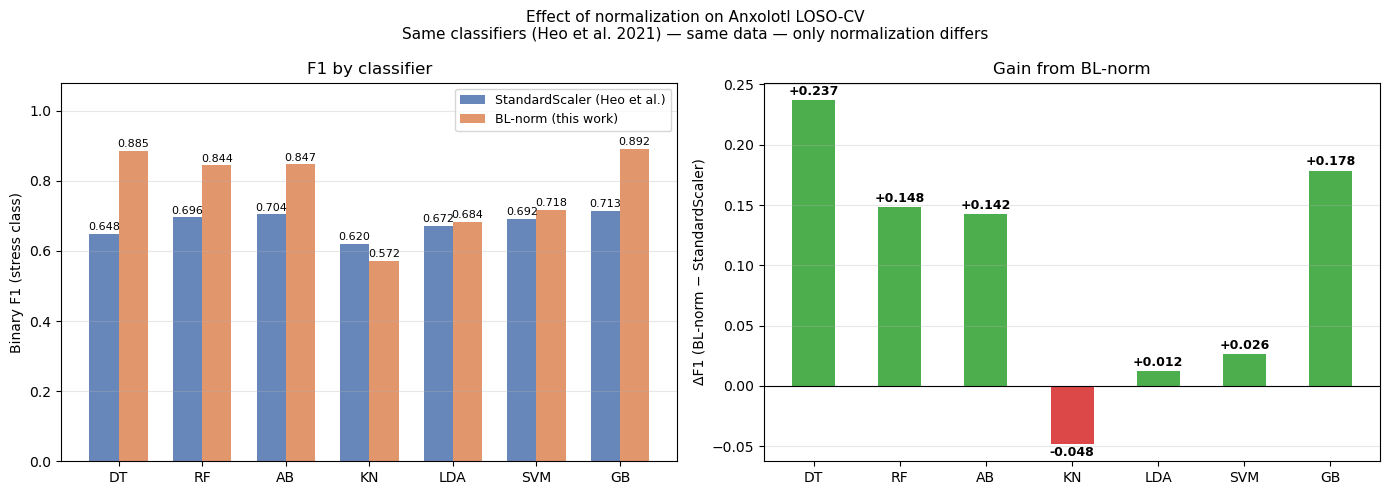

Saved to figures/heo2021_normalization_effect.png


In [6]:
f1_std_vals = [np.mean(res_std[n]['f1']) for n in clf_names]
f1_bl_vals  = [np.mean(res_bl[n]['f1'])  for n in clf_names]
delta_vals  = [b - s for b, s in zip(f1_bl_vals, f1_std_vals)]

x = np.arange(len(clf_names))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(
    'Effect of normalization on Anxolotl LOSO-CV\n'
    'Same classifiers (Heo et al. 2021) — same data — only normalization differs',
    fontsize=11
)

# Left: grouped bar
ax = axes[0]
bars_s = ax.bar(x - width/2, f1_std_vals, width, label='StandardScaler (Heo et al.)', color='#4C72B0', alpha=0.85)
bars_b = ax.bar(x + width/2, f1_bl_vals,  width, label='BL-norm (this work)',         color='#DD8452', alpha=0.85)
for bar in list(bars_s) + list(bars_b):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{bar.get_height():.3f}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(clf_names)
ax.set_ylabel('Binary F1 (stress class)')
ax.set_title('F1 by classifier')
ax.set_ylim(0, 1.08)
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)

# Right: delta bar
ax = axes[1]
colors = ['#2ca02c' if d >= 0 else '#d62728' for d in delta_vals]
bars_d = ax.bar(x, delta_vals, 0.5, color=colors, alpha=0.85)
for bar, d in zip(bars_d, delta_vals):
    ypos = bar.get_height() + 0.002 if d >= 0 else bar.get_height() - 0.012
    ax.text(bar.get_x() + bar.get_width()/2, ypos,
            f'{d:+.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_xticks(x); ax.set_xticklabels(clf_names)
ax.set_ylabel('ΔF1 (BL-norm − StandardScaler)')
ax.set_title('Gain from BL-norm')
ax.axhline(0, color='black', linewidth=0.8)
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('../figures/heo2021_normalization_effect.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to figures/heo2021_normalization_effect.png')

## Heo et al. WESAD results vs Anxolotl (both normalizations)

WESAD results are from the authors' published output file:  
`result/bi/ens/3/all_features_bp_time_ens.csv` (bp + time-domain filter + ensemble peak detection).  
Note: different dataset, different features, different signal type — not a direct comparison.

In [7]:
# From result/bi/ens/3/all_features_bp_time_ens.csv in the Heo et al. repo
WESAD_F1 = {'DT': 0.590, 'RF': 0.585, 'AB': 0.613, 'KN': 0.667,
             'LDA': 0.630, 'SVM': 0.625, 'GB': 0.611}

rows2 = []
for name in clf_names:
    rows2.append({
        'Classifier':             name,
        'WESAD F1 (Heo 2021)':   f'{WESAD_F1[name]:.3f}',
        'Anxolotl + StandardScaler': f'{np.mean(res_std[name]["f1"]):.3f}',
        'Anxolotl + BL-norm':    f'{np.mean(res_bl[name]["f1"]):.3f}',
    })

full_df = pd.DataFrame(rows2).set_index('Classifier')
print('Binary F1 — WESAD (Heo 2021) vs Anxolotl with two normalizations')
print('(WESAD uses different features extracted from raw PPG — different dataset)')
print()
print(full_df.to_string())

Binary F1 — WESAD (Heo 2021) vs Anxolotl with two normalizations
(WESAD uses different features extracted from raw PPG — different dataset)

           WESAD F1 (Heo 2021) Anxolotl + StandardScaler Anxolotl + BL-norm
Classifier                                                                 
DT                       0.590                     0.648              0.885
RF                       0.585                     0.696              0.844
AB                       0.613                     0.704              0.847
KN                       0.667                     0.620              0.572
LDA                      0.630                     0.672              0.684
SVM                      0.625                     0.692              0.718
GB                       0.611                     0.713              0.892


## Per-subject F1 heatmap — BL-norm

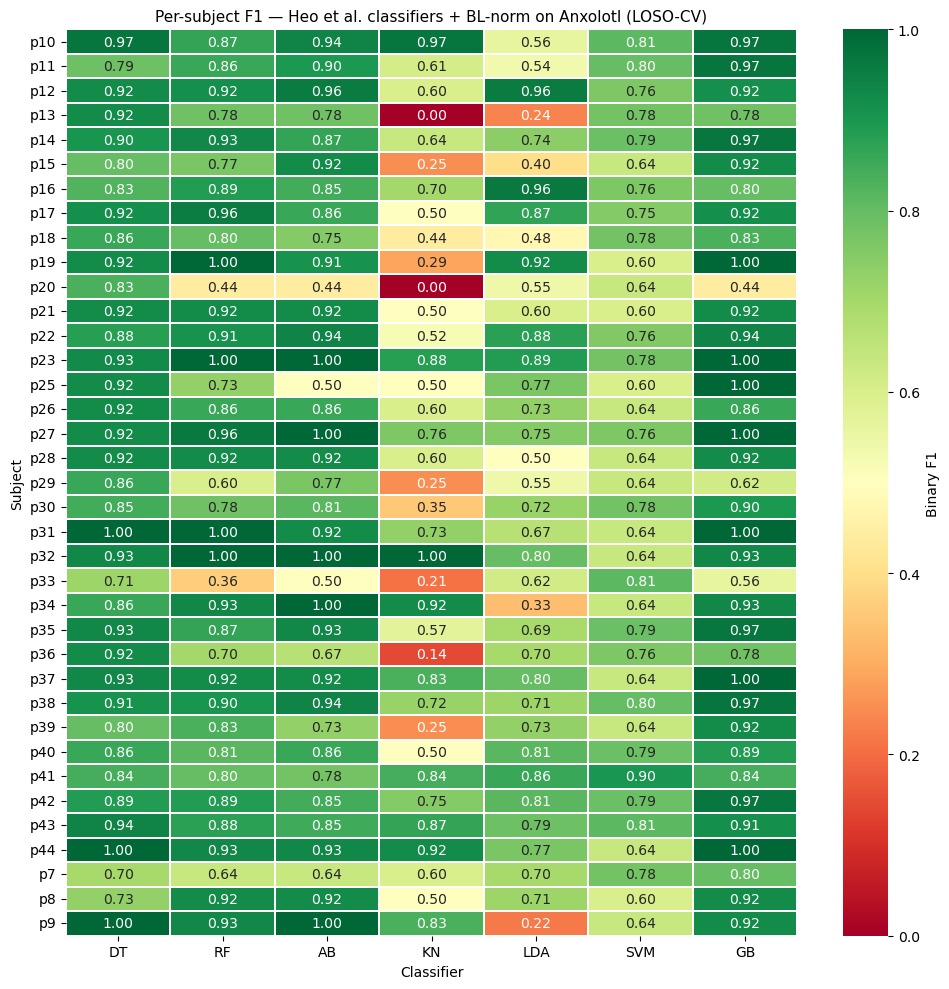

In [8]:
heatmap_data = pd.DataFrame(
    {name: res_bl[name]['f1'] for name in clf_names},
    index=subjects
)

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(
    heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn',
    vmin=0, vmax=1, ax=ax, linewidths=0.3, cbar_kws={'label': 'Binary F1'}
)
ax.set_title('Per-subject F1 — Heo et al. classifiers + BL-norm on Anxolotl (LOSO-CV)', fontsize=11)
ax.set_xlabel('Classifier'); ax.set_ylabel('Subject')
plt.tight_layout()
plt.savefig('../figures/heo2021_per_subject_f1.png', dpi=150, bbox_inches='tight')
plt.show()